# PARAMETROS H.DETECTION()

In [ ]:
!pip install herdingspikes==0.3.100 --no-build-isolation

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.7/373.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (pyproject.toml) ... done
  Created wheel for herdingspikes: filename=herdingspikes-0.3.100-cp312-cp312-linux_x86_64.whl size=1481889 sha256=6ee2c09a954108b7c3a8ed1cbfe8230b65fce75bccff49f5070dca112fd877cc
  Stored in directory: /root/.cache/pip/wheels/b0/fa/2b/9d86fcec018f8316f3b96e5fc4676250a4d145fce4458629d6
Successfully built herdingspikes


In [ ]:
from datetime import datetime
import sys, os
from herdingspikes.hs2 import HSDetection
from herdingspikes.hs2 import HSClustering
from herdingspikes.probe import BioCam
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylab

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Recording file
brw_file = ('/content/drive/Shareddrives/Lab 112/SAMP MEA/samp_2meses_p60 /AN5/SLC1/Phase_01.brw')
print(f'Recording file: {brw_file}')
out_file = brw_file.replace('.brw', '')

#Load BioCam recording
probe = BioCam(brw_file)
print(f'Channels: {probe.num_channels}')

Recording file: /content/drive/Shareddrives/Lab 112/SAMP MEA/samp_2meses_p60 /AN5/SLC1/Phase_01.brw
# 3Brain data format: 101 signal inversion 1.0
#       signal range:  -4125.0 -  4125.0
# Signal inversion looks like 1.0 , guessing the right method for data access.
# If your detection results look strange, signal polarity is wrong.

Channels: 4096


In [ ]:
#Load recording segment for noise inspection
t_start = 1_000_000
t_end = 1_100_000

data = probe.Read(t_start,t_end).reshape(t_end - t_start, probe.num_channels)
print(f'Loaded segment shape: {data.shape}')

#Detect noisy channels based on signal standard deviation
noise_threshold = 15
channel_std = np.std(data, axis=0)
masked_channels = np.where(channel_std > noise_threshold)[0]

print(
    f'Noisy channels detected: '
    f'{len(masked_channels)}')
print(*masked_channels, sep=',')

Loaded segment shape: (100000, 4096)
Noisy channels detected: 22
366,1078,1454,1471,1740,1860,2069,2277,2455,2456,2518,2519,2520,2521,2582,2583,2584,2647,2911,2956,3089,3673


In [ ]:
threshold = 30 # detection threshold
to_localize = True  # set to False if spikes should only be detected, not localised (will break sorting)
save_all = True
left_cutout_ms = 5.0  #  the number of milliseconds, before the spike, to be included in the spike shape
right_cutout_ms = 5.0  #  the number of milliseconds, after the spike, to be included in the spike shape
amp_evaluation_time = 0.4 # the number of ms during which the trace is integrated, for evaluating amplitude, later comparison with 'maa'
spk_evaluation_time = 1.7

In [ ]:
maskedch = [366,1078,1454,1471,1740,1860,2069,2277,2455,2456,2518,2519,2520,2521,2582,2583,2584,2647,2911,2956,3089,3673]
print(f'Masked Channels: {np.size(maskedch)}, first 10: {maskedch[:10]}')

#Reload BioCam object with masked channels
probe = BioCam(brw_file, masked_channels=maskedch)

Masked Channels: 22, first 10: [366, 1078, 1454, 1471, 1740, 1860, 2069, 2277, 2455, 2456]
# 3Brain data format: 101 signal inversion 1.0
#       signal range:  -4125.0 -  4125.0
# Signal inversion looks like 1.0 , guessing the right method for data access.
# If your detection results look strange, signal polarity is wrong.



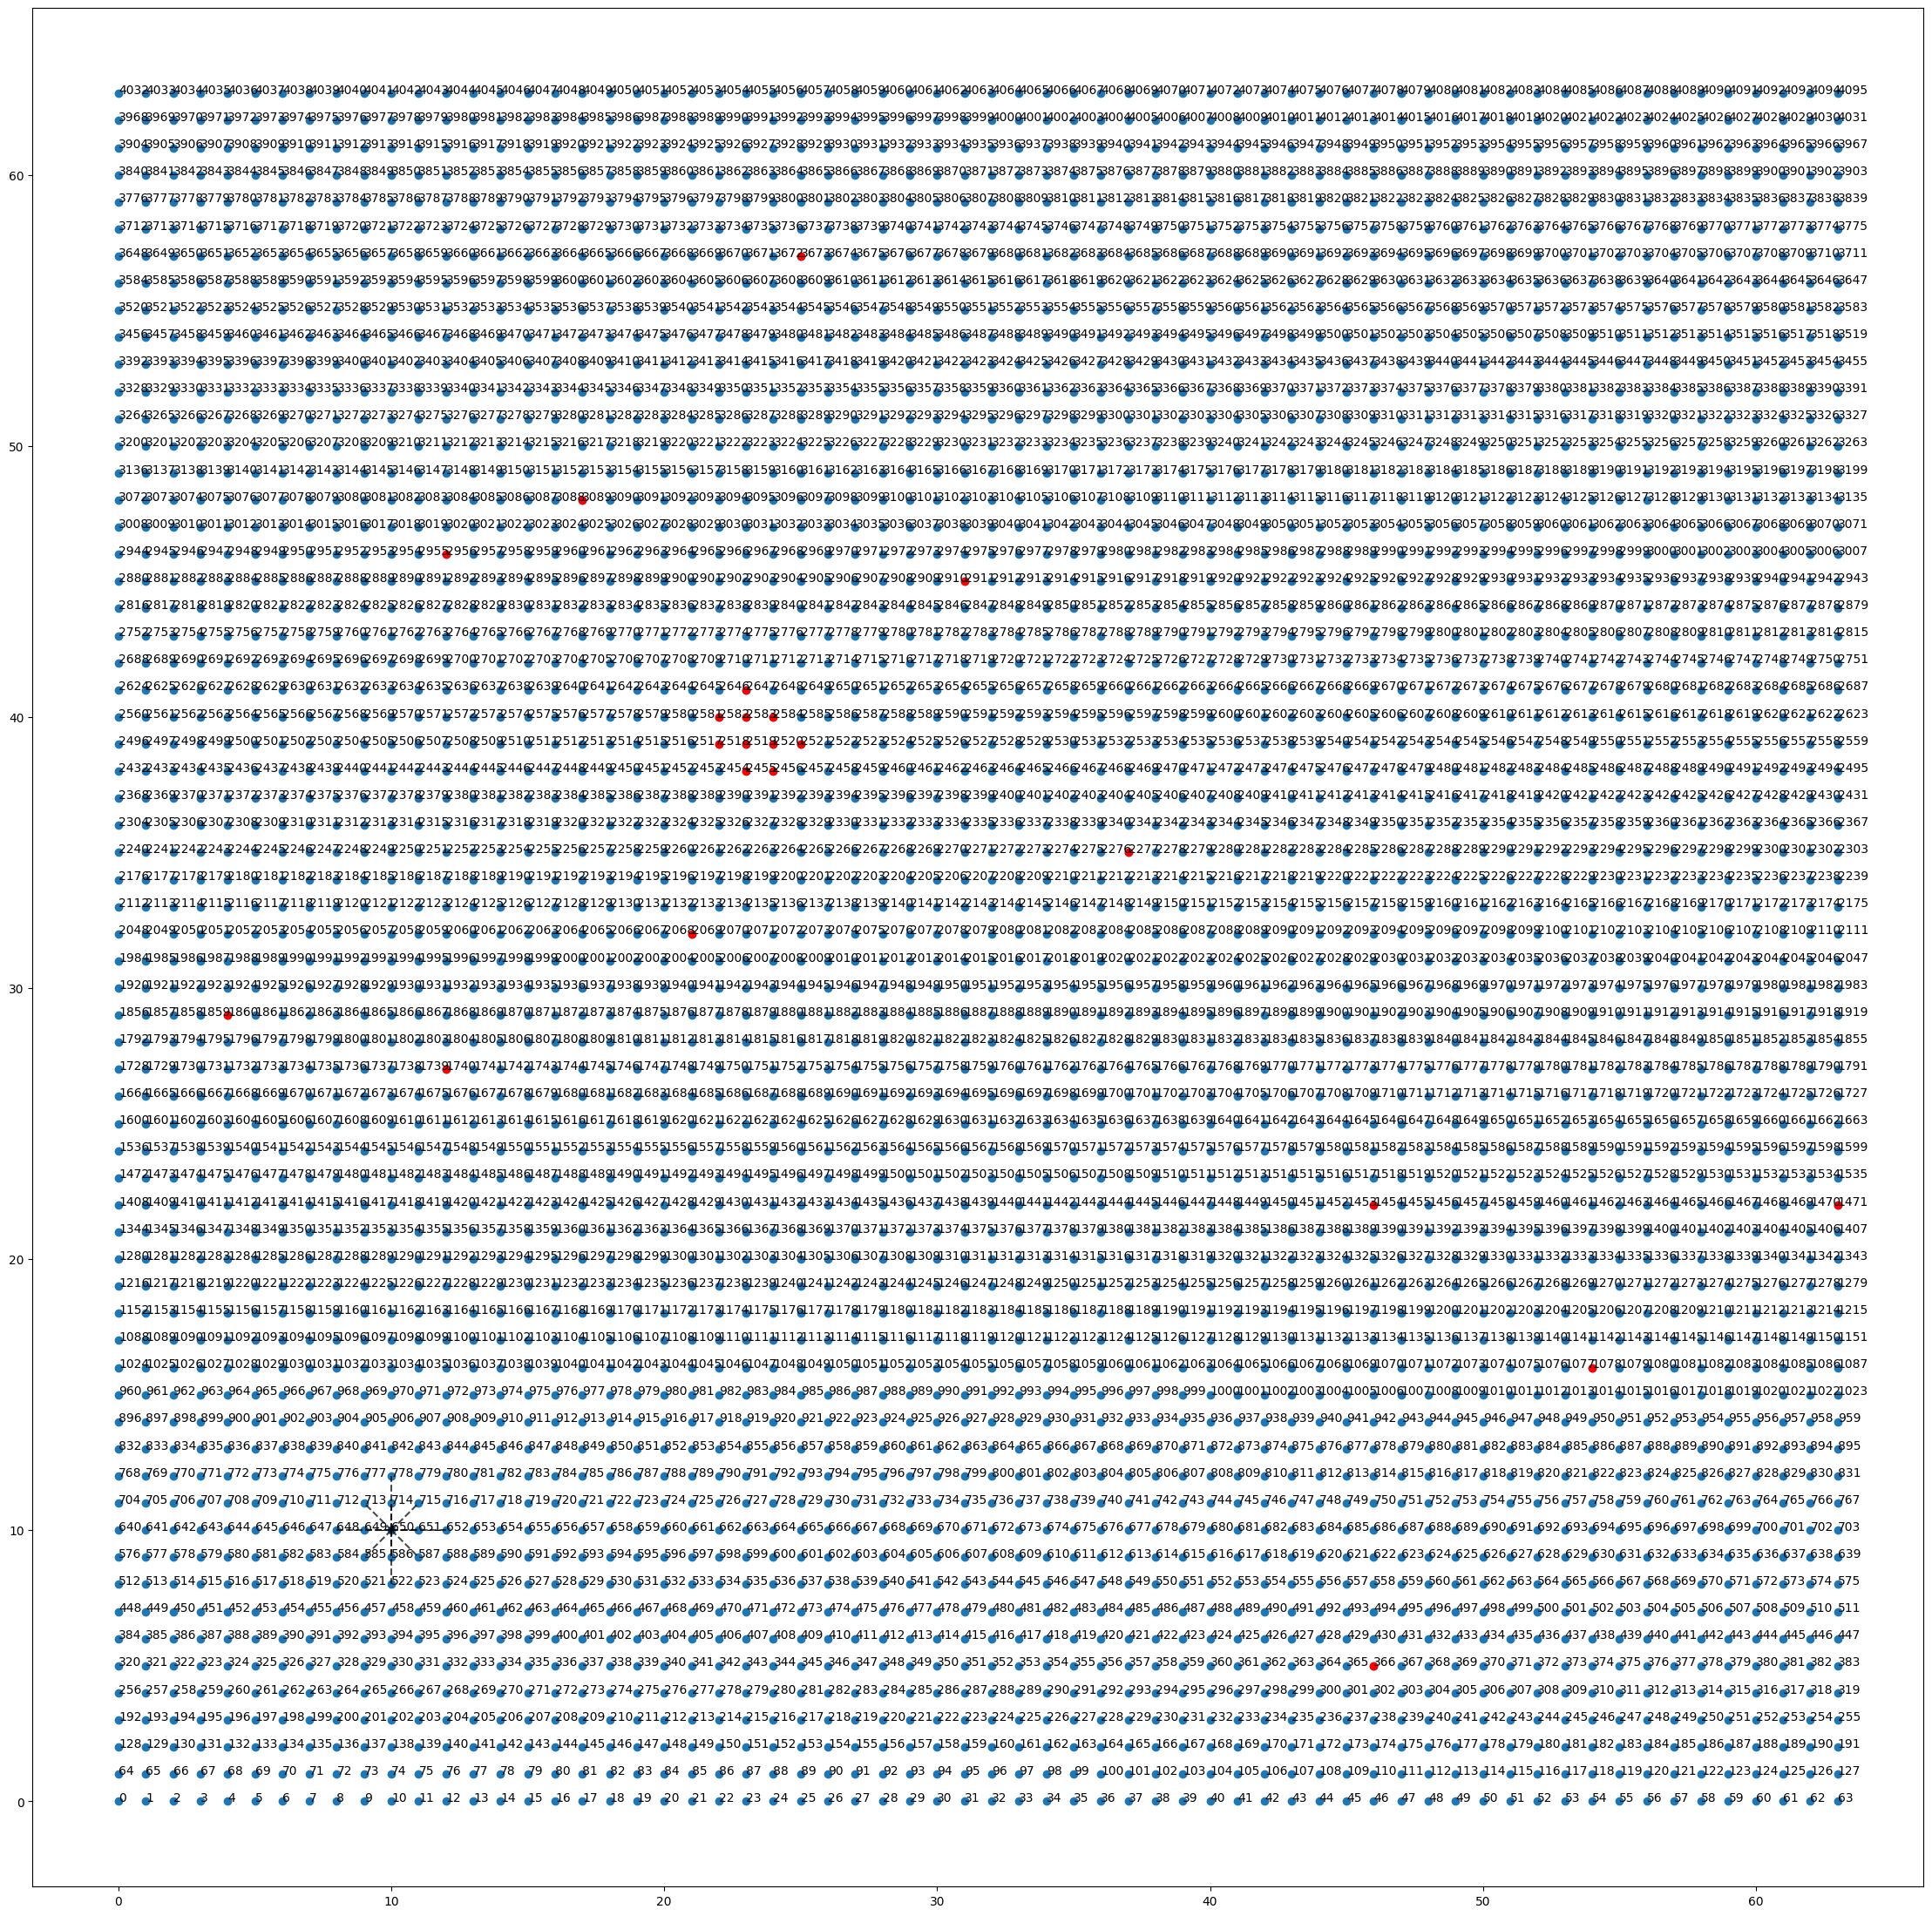

In [ ]:
probe.show(show_neighbors=[650], figwidth=28)

# SPIKE DETECTION

In [ ]:
H = HSDetection(probe, num_com_centers=1, threshold=threshold, to_localize=to_localize,
                maa=0, ahpthr=0, out_file_name=out_file, save_all=save_all,
                left_cutout_time=left_cutout_ms, right_cutout_time=right_cutout_ms,
                amp_evaluation_time=amp_evaluation_time, spk_evaluation_time=spk_evaluation_time,
                file_directory_name='analysis', decay_filtering=True)

In [ ]:
H.DetectFromRaw()

# Masking Channels: [321, 434, 1042, 1093, 1103, 1155, 1156, 1157, 1160, 1163, 1164, 1165, 1166, 1167, 1219, 1225, 1228, 1229, 1292, 1293, 1420, 1673, 2186, 2386, 2454, 2455, 2456, 2457, 2517, 2518, 2519, 2520, 2521, 2567, 2582, 2583, 2584, 2585, 2646, 2647, 2648, 2649, 3162, 3665]
# Sampling rate: 7062
# Localization On
# Writing out extended detection info
# Number of recorded channels: 4096
# Analysing frames: 4237234; Seconds: 600.0048145001416
# Frames before spike in cutout: 35
# Frames after spike in cutout: 35
# tcuts: 47 47
# tInc: 50000
# Analysing frames from -47 to 50047  (0.0%)
# Analysing frames from 49953 to 100047  (1.2%)
# Analysing frames from 99953 to 150047  (2.4%)
# Analysing frames from 149953 to 200047  (3.5%)
# Analysing frames from 199953 to 250047  (4.7%)
# Analysing frames from 249953 to 300047  (5.9%)
# Analysing frames from 299953 to 350047  (7.1%)
# Analysing frames from 349953 to 400047  (8.3%)
# Analysing frames from 399953 to 450047  (9.4%)
# Analysing 

In [ ]:
H.LoadDetected()

Loaded 1795 spikes.


In [ ]:
H.spikes

,ch,t,Amplitude,x,y,Shape
0,1894,1080,6228,37.959,28.985,"[-2, -11, -6, -5, -3, 14, 8, 9, 0, 15, -6, -10..."
1,1959,27622,9912,38.874,30.022,"[-7, 4, -13, 5, -1, -7, -4, -17, 8, 2, 5, 5, 9..."
2,1894,41504,5756,37.982,28.941,"[-24, 4, -24, 11, -1, 0, 3, -4, 0, -2, 0, -19,..."
3,1335,50421,5071,55.057,20.131,"[-10, -23, -10, -2, 16, 13, 5, 37, -24, -25, -..."
4,1894,57256,6704,37.962,29.037,"[1, 3, 9, 16, 7, 6, -16, -16, -4, 8, -4, -8, -..."
...,...,...,...,...,...,...
1790,1894,4223823,6144,37.771,29.113,"[8, 10, -5, 2, -22, -27, -9, 0, -9, -12, -7, 1..."
1791,1509,4223834,23585,36.951,22.588,"[-1, 7, -10, -36, -45, -41, -13, -31, -25, -41..."
1792,1381,4223838,9775,37.287,21.692,"[-30, -15, -15, -28, -36, -31, -27, -22, -13, ..."
1793,313,4229921,5925,57.029,3.972,"[-24, -8, 5, 4, -1, 11, 15, -7, 2, -25, -32, -..."


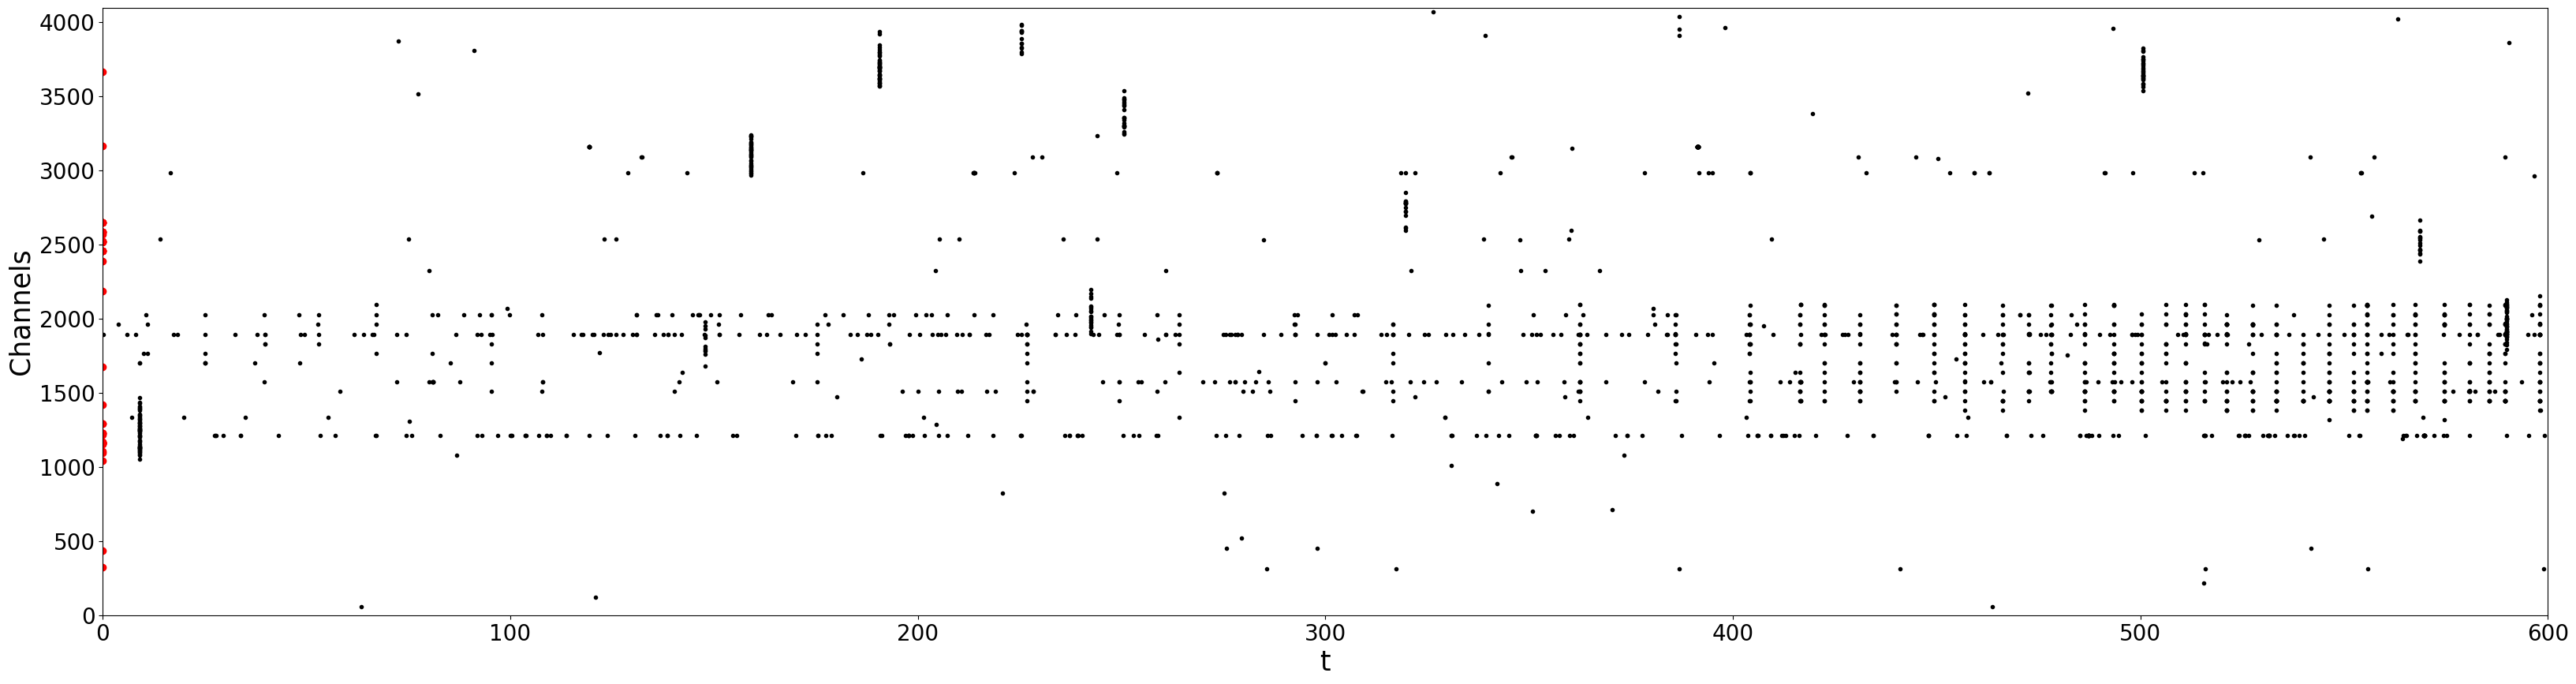

In [ ]:
#Raster Plot
fig=plt.figure(figsize=(40, 10))
plt.plot(H.spikes.t/7062.0, H.spikes.ch,'.', color='black')
plt.plot(np.zeros(len(maskedch)),maskedch,'o', color='red')
plt.grid(False)
plt.xlabel('t', fontsize=25)
plt.ylabel('Channels', fontsize=25)
plt.xlim(0, 600)
plt.ylim(0, 4096)
plt.xticks(fontsize=20);
plt.yticks(fontsize=20);

figName = brw_file[0:-4]+'_Raster_original_thr25.jpg'
fig.savefig(figName)

In [ ]:
#Save the DataFrame to CSV
df = pd.read_csv('H.spikes', sep=',', header=0, names=['channel', 'time', 'amplitude', 'x', 'y', 'waveform'])

output_filename = 'df_spikes.csv'
df.to_csv(output_filename, index=False)
print(f'DataFrame saved successfully to: {output_filename}')

DataFrame saved successfully to: df_spikes.csv





Channels with less than 5 events:
746, 3887, 2657, 2208, 1478, 2819, 2673, 2385, 3809, 3807, 3869, 3258, 4002, 4061, 3556, 3880, 3882, 3881, 3427, 3421, 3418, 3821, 3627, 3498, 3630, 3284, 1350, 3912, 1470, 1977, 3655, 1092, 3564, 3994, 2665, 1482, 3947, 3728, 4056, 3742, 3754, 349, 4053, 1413, 1477, 3697, 3676, 3499, 3934, 3942, 123, 2522, 728, 3668, 3462, 3783, 3105, 795, 3342, 1284, 3174, 3752, 934, 2326, 1059, 740, 1122, 675, 993, 1066, 990, 2209, 347, 2508, 1159, 308, 437, 3885, 3695, 168, 2391, 702, 2226, 48, 1174, 232, 3681, 4000, 4065, 3625, 4067, 3691, 3629, 3113, 4047, 1168, 998, 996


In [ ]:
def parse_shape(shape_str):
    shape_str = shape_str.strip("[]")
    return np.array([float(x) for x in shape_str.split()])

channels = df['channel'].unique()
n_channels = len(channels)
n_cols = 5
n_lines = int(np.ceil(n_channels / n_cols))
fig, axs = plt.subplots(n_lines, n_cols, figsize=(15, n_lines * 3))
axs = axs.flatten()

lowactivity_channels = []
for i, channel in enumerate(channels):
    df_channel = df[df['channel'] == channel]
    events = len(df_channel)

    if events < 5:
        lowactivity_channels.append(int(channel))

    #Plot
    for _, row in df_channel.iterrows():
        shape_array = parse_shape(row['waveform'])
        axs[i].plot(shape_array, alpha=0.5)

    axs[i].set_title(f'channel {channel}')
    axs[i].set_xlabel('Channel')
    axs[i].set_ylabel('Amp')

for j in range(i + 1, len(axs)):
    fig.delaxes(axs[j])
plt.tight_layout()
plt.show()

if lowactivity_channels:
    canais_str = ', '.join(map(str, lowactivity_channels))
    print("\nChannels with less than 5 events:")
    print(canais_str)
else:
    print("\nAll good.")